<a href="https://colab.research.google.com/github/Qil06/intelegent-system/blob/main/Yu_Gi_Oh_supervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Yu-Gi-Oh-Normal_Monsters.csv to Yu-Gi-Oh-Normal_Monsters (1).csv


In [ ]:
import pandas  as pd

df = pd.read_csv("Yu-Gi-Oh-Normal_Monsters.csv")

In [ ]:
print(df.head())
print(df.info())
print(df.isnull().sum)

                 Name Attributes Sub-Types  Level Attack_Points Defense_Points
0      7 Colored Fish      Water      Fish      4          1800            800
1      Acrobat Monkey      Earth   Machine      3          1000           1800
2               Aitsu       Fire     Fairy      5           100            100
3  Alexandrite Dragon      Light    Dragon      4          2000            100
4  Alien Shocktrooper      Earth   Reptile      4          1900            800
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Name            478 non-null    object
 1   Attributes      478 non-null    object
 2   Sub-Types       478 non-null    object
 3   Level           478 non-null    int64 
 4   Attack_Points   478 non-null    object
 5   Defense_Points  477 non-null    object
dtypes: int64(1), object(5)
memory usage: 22.5+ KB
None
<bound method 

In [ ]:
print(df['Attributes'].value_counts())
print(df['Sub-Types'].value_counts())

Attributes
Earth     171
Dark      109
Water      66
Light      53
Wind       43
Fire       32
Divine      3
FIRE        1
Name: count, dtype: int64
Sub-Types
Warrior        51
Beast          50
Fiend          46
Machine        44
Dragon         34
Aqua           31
Spellcaster    28
Fairy          22
Insect         21
Rock           20
Zombie         18
Winged         18
Pyro           17
Fish           16
Dinosaur       14
Reptile        11
Plant           9
Thunder         8
Sea             6
Cyberse         5
Psychic         3
Wyrm            3
Divine          3
Name: count, dtype: int64


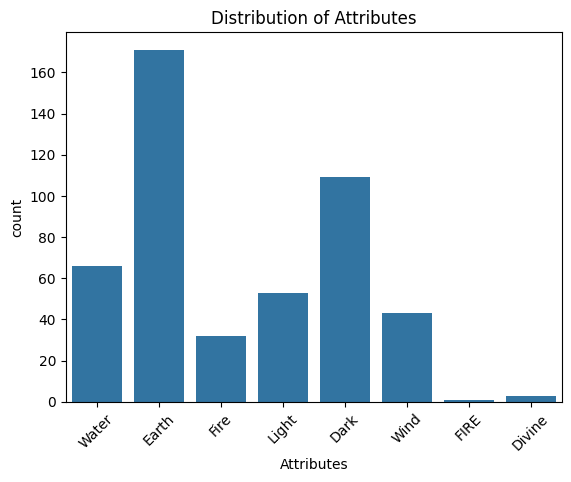

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Attributes')
plt.title("Distribution of Attributes")
plt.xticks (rotation=45)
plt.show()

In [ ]:
common_types = ['Dragon', 'Warrior', 'Fiend', 'Machine', 'Aqua', 'Spellcaster']
df_filtered = df [df ['Sub-Types'].isin (common_types)]

In [ ]:
from sklearn.preprocessing import LabelEncoder
le_attr = LabelEncoder()
df_filtered['Attr_Code'] = le_attr.fit_transform(df_filtered['Attributes'])

/tmp/ipykernel_8730/463569136.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Attr_Code'] = le_attr.fit_transform(df_filtered['Attributes'])


In [ ]:
X = df_filtered [['Attr_Code', 'Attack_Points', 'Defense_Points']]
y = df_filtered['Sub-Types']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier (random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

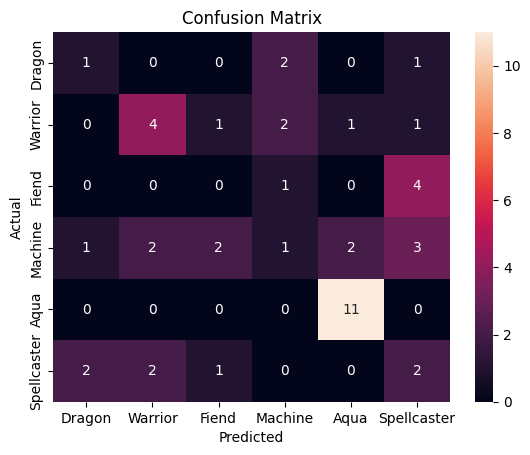

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred, labels = common_types)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=common_types, yticklabels=common_types)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


Confusion Matrix for Sub-Type: Dragon


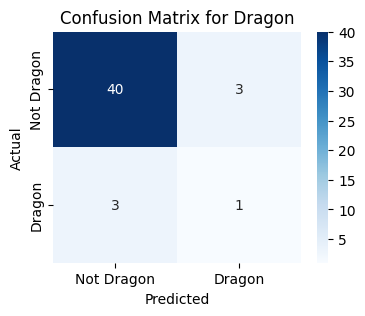


Confusion Matrix for Sub-Type: Warrior


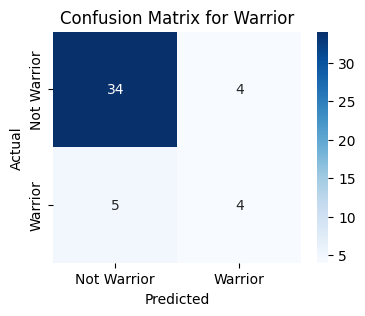


Confusion Matrix for Sub-Type: Fiend


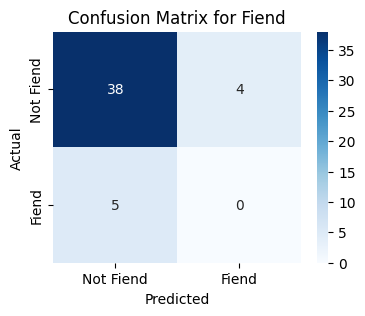


Confusion Matrix for Sub-Type: Machine


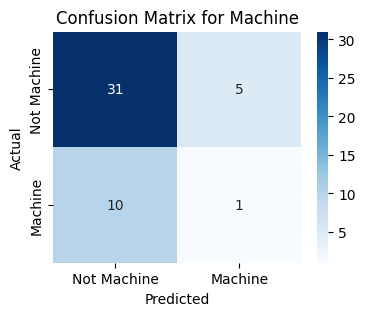


Confusion Matrix for Sub-Type: Aqua


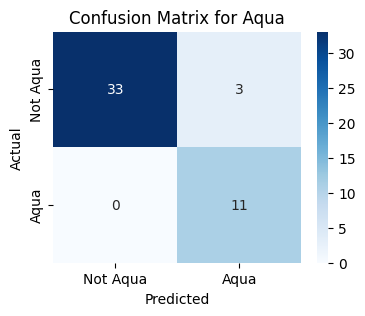


Confusion Matrix for Sub-Type: Spellcaster


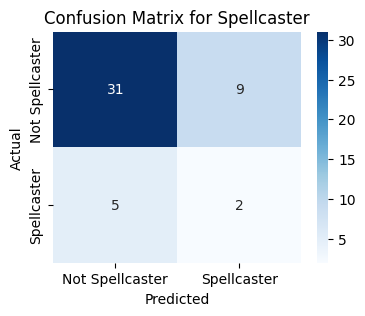

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Display colored confusion matrix for each subtype
for subtype in common_types:
    print(f"\nConfusion Matrix for Sub-Type: {subtype}")
    # Create binary predictions and true labels for the current subtype
    y_true_subtype = (y_test == subtype)
    y_pred_subtype = (y_pred == subtype)

    # Calculate confusion matrix
    cm_subtype = confusion_matrix(y_true_subtype, y_pred_subtype)

    # Display the confusion matrix as a heatmap
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm_subtype, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Not ' + subtype, subtype],
                yticklabels=['Not ' + subtype, subtype])

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix for {subtype}")
    plt.show()